## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
import math
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset

# Scikit-learn imports
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

print("✅ Libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

✅ Libraries imported successfully!
PyTorch version: 2.5.1+cu121
NumPy version: 1.26.4
Pandas version: 2.1.4


## 2. Check GPU Availability

In [2]:
# Check GPU availability
print("Checking GPU availability...")
print("="*60)

if torch.cuda.is_available():
    device = torch.device('cuda')
    print("✅ GPU FOUND!")
    print(f"   Device: {torch.cuda.get_device_name(0)}")
    print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    print(f"   CUDA Version: {torch.version.cuda}")
else:
    device = torch.device('cpu')
    print("⚠️  GPU not available, using CPU")

print("="*60)
print(f"Training device: {device}")
print("="*60)

Checking GPU availability...
✅ GPU FOUND!
   Device: NVIDIA GeForce RTX 4060 Laptop GPU
   Memory: 8.59 GB
   CUDA Version: 12.1
Training device: cuda


## 3. Define EEG-ITNet Architecture

In [4]:
class ChannelAttention(nn.Module):
    """Channel-wise attention mechanism"""
    def __init__(self, in_channels, reduction_ratio=16):
        super(ChannelAttention, self).__init__()
        
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        
        self.fc = nn.Sequential(
            nn.Linear(in_channels, in_channels // reduction_ratio, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(in_channels // reduction_ratio, in_channels, bias=False)
        )
        
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        # x shape: (batch, channels, height, width)
        b, c, h, w = x.size()
        
        # Average pooling
        avg_out = self.fc(self.avg_pool(x).view(b, c))
        # Max pooling
        max_out = self.fc(self.max_pool(x).view(b, c))
        
        # Combine and apply sigmoid
        attention = self.sigmoid(avg_out + max_out).view(b, c, 1, 1)
        
        return x * attention


class InceptionModule(nn.Module):
    """Inception-Time module with multiple kernel sizes"""
    def __init__(self, in_channels, out_channels, kernel_sizes=[5, 11, 23], bottleneck=True):
        super(InceptionModule, self).__init__()
        
        self.bottleneck = bottleneck
        
        if bottleneck:
            # Bottleneck layer to reduce computation
            self.bottleneck_conv = nn.Conv2d(in_channels, out_channels // 4, kernel_size=1, bias=False)
            self.bottleneck_bn = nn.BatchNorm2d(out_channels // 4)
            conv_in_channels = out_channels // 4
        else:
            conv_in_channels = in_channels
        
        # Multiple convolution branches with different kernel sizes
        # Total branches = len(kernel_sizes) + 1 (for maxpool)
        n_branches = len(kernel_sizes) + 1
        branch_channels = out_channels // n_branches
        
        self.conv_branches = nn.ModuleList()
        for kernel_size in kernel_sizes:
            padding = kernel_size // 2
            branch = nn.Sequential(
                nn.Conv2d(conv_in_channels, branch_channels, 
                         kernel_size=(1, kernel_size), padding=(0, padding), bias=False),
                nn.BatchNorm2d(branch_channels),
                nn.ReLU(inplace=True)
            )
            self.conv_branches.append(branch)
        
        # Max pooling branch
        self.maxpool_branch = nn.Sequential(
            nn.MaxPool2d(kernel_size=(1, 3), stride=1, padding=(0, 1)),
            nn.Conv2d(conv_in_channels, branch_channels, 
                     kernel_size=1, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.ReLU(inplace=True)
        )
        
        # Channel attention
        self.channel_attention = ChannelAttention(out_channels)
        
        # Residual connection
        if in_channels != out_channels:
            self.residual = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.residual = nn.Identity()
        
        self.final_activation = nn.ReLU(inplace=True)
        
    def forward(self, x):
        residual = self.residual(x)
        
        # Apply bottleneck if enabled
        if self.bottleneck:
            x = F.relu(self.bottleneck_bn(self.bottleneck_conv(x)))
        
        # Apply multiple convolution branches
        branch_outputs = []
        for branch in self.conv_branches:
            branch_outputs.append(branch(x))
        
        # Add max pooling branch
        branch_outputs.append(self.maxpool_branch(x))
        
        # Concatenate all branches
        out = torch.cat(branch_outputs, dim=1)
        
        # Apply channel attention
        out = self.channel_attention(out)
        
        # Add residual connection
        out = out + residual
        
        return self.final_activation(out)


class EEGSpatialConv(nn.Module):
    """Spatial convolution for EEG channels"""
    def __init__(self, in_channels=1, out_channels=64, n_eeg_channels=14):
        super(EEGSpatialConv, self).__init__()
        
        # Temporal convolution
        self.temporal_conv = nn.Conv2d(in_channels, out_channels, 
                                     kernel_size=(1, 25), padding=(0, 12), bias=False)
        self.temporal_bn = nn.BatchNorm2d(out_channels)
        
        # Spatial convolution (depthwise)
        self.spatial_conv = nn.Conv2d(out_channels, out_channels * 2, 
                                    kernel_size=(n_eeg_channels, 1), groups=out_channels, bias=False)
        self.spatial_bn = nn.BatchNorm2d(out_channels * 2)
        
        self.activation = nn.ELU(inplace=True)
        self.dropout = nn.Dropout(0.25)
        
    def forward(self, x):
        # Temporal convolution
        x = self.temporal_conv(x)
        x = self.temporal_bn(x)
        
        # Spatial convolution
        x = self.spatial_conv(x)
        x = self.spatial_bn(x)
        x = self.activation(x)
        x = self.dropout(x)
        
        return x


class EEGITNet(nn.Module):
    """
    EEG Inception-Time Network for EEG Classification
    
    Combines spatial filtering for EEG with Inception-Time modules
    for multi-scale temporal feature extraction.
    
    Parameters:
        n_classes (int): Number of output classes
        n_channels (int): Number of EEG channels
        n_samples (int): Number of time samples
        n_inception_blocks (int): Number of Inception modules
        inception_channels (list): Number of channels in each Inception block
        kernel_sizes (list): Kernel sizes for Inception modules
        dropout_rate (float): Dropout rate
    """
    def __init__(self, n_classes=4, n_channels=14, n_samples=128,
                 n_inception_blocks=3, inception_channels=[64, 128, 256],
                 kernel_sizes=[5, 11, 23], dropout_rate=0.5):
        super(EEGITNet, self).__init__()
        
        self.n_classes = n_classes
        self.n_channels = n_channels
        self.n_samples = n_samples
        
        # Initial spatial convolution for EEG
        self.spatial_conv = EEGSpatialConv(in_channels=1, out_channels=32, n_eeg_channels=n_channels)
        
        # Pooling after spatial convolution
        self.pool1 = nn.AvgPool2d(kernel_size=(1, 4))
        
        # Inception-Time blocks
        self.inception_blocks = nn.ModuleList()
        in_channels = 64  # Output from spatial conv
        
        for i in range(n_inception_blocks):
            out_channels = inception_channels[i] if i < len(inception_channels) else inception_channels[-1]
            
            inception_block = InceptionModule(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_sizes=kernel_sizes,
                bottleneck=True
            )
            self.inception_blocks.append(inception_block)
            
            # Add pooling between blocks
            if i < n_inception_blocks - 1:
                pool = nn.AvgPool2d(kernel_size=(1, 2))
                self.inception_blocks.append(pool)
            
            in_channels = out_channels
        
        # Global average pooling
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        
        # Final classifier
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(inception_channels[-1], inception_channels[-1] // 2),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout_rate / 2),
            nn.Linear(inception_channels[-1] // 2, n_classes)
        )
        
    def forward(self, x):
        # x shape: (batch, 1, n_channels, n_samples)
        
        # Spatial convolution for EEG
        x = self.spatial_conv(x)
        x = self.pool1(x)
        
        # Apply Inception-Time blocks
        for block in self.inception_blocks:
            x = block(x)
        
        # Global average pooling
        x = self.global_pool(x)
        x = x.view(x.size(0), -1)  # Flatten
        
        # Classification
        x = self.classifier(x)
        
        return x


# Test model initialization
print("Testing EEG-ITNet architecture...")
model_test = EEGITNet(n_classes=4, n_channels=14, n_samples=128,
                      n_inception_blocks=3, inception_channels=[64, 128, 256])
test_input = torch.randn(2, 1, 14, 128)
test_output = model_test(test_input)
print(f"✅ EEG-ITNet initialized successfully!")
print(f"   Input shape: {test_input.shape}")
print(f"   Output shape: {test_output.shape}")
print(f"   Number of parameters: {sum(p.numel() for p in model_test.parameters()):,}")
print(f"   Trainable parameters: {sum(p.numel() for p in model_test.parameters() if p.requires_grad):,}")

Testing EEG-ITNet architecture...
✅ EEG-ITNet initialized successfully!
   Input shape: torch.Size([2, 1, 14, 128])
   Output shape: torch.Size([2, 4])
   Number of parameters: 315,204
   Trainable parameters: 315,204


## 4. Load Pre-saved Fold Data

In [5]:
# Define data directory
FOLD_DIR = Path("trainfold")
n_splits = 5

# Class mapping
class_names = ['Apple', 'Car', 'Flower', 'Human Face']
class_map = {1: 'Apple', 2: 'Car', 3: 'Flower', 4: 'Human Face'}

print("="*60)
print("LOADING PRE-SAVED FOLD DATA")
print("="*60)
print(f"Fold directory: {FOLD_DIR}")
print(f"Number of folds: {n_splits}")

# Verify folds exist
for fold_num in range(1, n_splits + 1):
    fold_path = FOLD_DIR / f"fold_{fold_num}"
    train_file = fold_path / "train.csv"
    test_file = fold_path / "test.csv"
    
    if train_file.exists() and test_file.exists():
        train_df = pd.read_csv(train_file)
        test_df = pd.read_csv(test_file)
        print(f"\n✅ Fold {fold_num}:")
        print(f"   Train: {len(train_df)} samples")
        print(f"   Test:  {len(test_df)} samples")
    else:
        print(f"\n❌ Fold {fold_num}: Files not found!")

print("\n" + "="*60)
print("All folds verified successfully!")
print("="*60)

LOADING PRE-SAVED FOLD DATA
Fold directory: trainfold
Number of folds: 5

✅ Fold 1:
   Train: 2889 samples
   Test:  723 samples

✅ Fold 1:
   Train: 2889 samples
   Test:  723 samples

✅ Fold 2:
   Train: 2889 samples
   Test:  723 samples

✅ Fold 2:
   Train: 2889 samples
   Test:  723 samples

✅ Fold 3:
   Train: 2890 samples
   Test:  722 samples

✅ Fold 3:
   Train: 2890 samples
   Test:  722 samples

✅ Fold 4:
   Train: 2890 samples
   Test:  722 samples

✅ Fold 4:
   Train: 2890 samples
   Test:  722 samples

✅ Fold 5:
   Train: 2890 samples
   Test:  722 samples

All folds verified successfully!

✅ Fold 5:
   Train: 2890 samples
   Test:  722 samples

All folds verified successfully!


## 5. Data Preprocessing Functions

In [6]:
def prepare_itnet_data(df, scaler=None, fit_scaler=True):
    """
    Prepare data for EEG-ITNet input
    
    Parameters:
        df: DataFrame with features and Class column
        scaler: StandardScaler object (optional)
        fit_scaler: Whether to fit the scaler (True for train, False for test)
    
    Returns:
        X_reshaped: Data in shape (n_samples, 1, n_channels, n_timepoints)
        y: Labels (0-indexed)
        scaler: Fitted scaler object
    """
    # Separate features and labels
    X = df.iloc[:, :-1].values  # All columns except last (Class)
    y = df.iloc[:, -1].values   # Last column (Class)
    
    # Encode labels to 0-based indexing (1,2,3,4 -> 0,1,2,3)
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)
    
    # Standardize features
    if scaler is None:
        scaler = StandardScaler()
    
    if fit_scaler:
        X_scaled = scaler.fit_transform(X)
    else:
        X_scaled = scaler.transform(X)
    
    # Reshape for ITNet: (n_samples, n_features) -> (n_samples, 1, n_channels, n_timepoints)
    # Features: 14 channels × 128 timepoints = 1792 features
    n_samples = X_scaled.shape[0]
    n_channels = 14
    n_timepoints = 128
    
    X_reshaped = X_scaled.reshape(n_samples, n_channels, n_timepoints)
    X_reshaped = np.expand_dims(X_reshaped, axis=1)  # Add channel dimension
    
    return X_reshaped, y_encoded, scaler

# Test the function
print("Testing data preparation function...")
test_df = pd.read_csv(FOLD_DIR / "fold_1" / "train.csv")
X_test, y_test, scaler_test = prepare_itnet_data(test_df)
print(f"✅ Data preparation successful!")
print(f"   Input shape: {X_test.shape}")
print(f"   Expected: (n_samples, 1, 14, 128)")
print(f"   Labels shape: {y_test.shape}")
print(f"   Unique labels: {np.unique(y_test)}")
print(f"   Label range: [{y_test.min()}, {y_test.max()}]")

Testing data preparation function...
✅ Data preparation successful!
   Input shape: (2889, 1, 14, 128)
   Expected: (n_samples, 1, 14, 128)
   Labels shape: (2889,)
   Unique labels: [0 1 2 3]
   Label range: [0, 3]
✅ Data preparation successful!
   Input shape: (2889, 1, 14, 128)
   Expected: (n_samples, 1, 14, 128)
   Labels shape: (2889,)
   Unique labels: [0 1 2 3]
   Label range: [0, 3]


## 6. Training Functions

In [7]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """Train for one epoch"""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        # Zero the parameter gradients
        optimizer.zero_grad()
        
        # Forward
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        # Backward + optimize
        loss.backward()
        
        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # Statistics
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100 * correct / total
    
    return epoch_loss, epoch_acc

def evaluate(model, test_loader, criterion, device):
    """Evaluate the model"""
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            # Forward
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            # Statistics
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    epoch_loss = running_loss / len(test_loader)
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    
    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    f1_weighted = f1_score(all_labels, all_preds, average='weighted')
    precision = precision_score(all_labels, all_preds, average='macro')
    recall = recall_score(all_labels, all_preds, average='macro')
    cm = confusion_matrix(all_labels, all_preds)
    
    return {
        'loss': epoch_loss,
        'accuracy': accuracy,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'precision': precision,
        'recall': recall,
        'confusion_matrix': cm,
        'predictions': all_preds,
        'labels': all_labels
    }

print("✅ Training functions defined successfully!")

✅ Training functions defined successfully!


## 7. Train EEG-ITNet with 5-Fold Cross-Validation

In [8]:
# Hyperparameters
BATCH_SIZE = 32
LEARNING_RATE = 0.001  # Higher LR than Transformer
NUM_EPOCHS = 100
PATIENCE = 15  # Early stopping patience

# Model parameters
N_INCEPTION_BLOCKS = 3
INCEPTION_CHANNELS = [64, 128, 256]
KERNEL_SIZES = [5, 11, 23]
DROPOUT_RATE = 0.5

# Storage for results
itnet_fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision_macro': [],
    'recall_macro': [],
    'confusion_matrices': [],
    'train_history': [],
    'val_history': []
}

print("="*80)
print(f"Training EEG-ITNet - 5-Fold Cross-Validation on {device}")
print("="*80)
print(f"Hyperparameters:")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Learning rate: {LEARNING_RATE}")
print(f"  Max epochs: {NUM_EPOCHS}")
print(f"  Early stopping patience: {PATIENCE}")
print(f"\nModel Architecture:")
print(f"  Inception blocks: {N_INCEPTION_BLOCKS}")
print(f"  Inception channels: {INCEPTION_CHANNELS}")
print(f"  Kernel sizes: {KERNEL_SIZES}")
print(f"  Dropout rate: {DROPOUT_RATE}")
print("="*80)

# Train on each fold
for fold_num in range(1, n_splits + 1):
    print(f"\n{'='*80}")
    print(f"FOLD {fold_num}/{n_splits}")
    print(f"{'='*80}")
    
    # Load data from pre-saved folds
    train_df = pd.read_csv(FOLD_DIR / f"fold_{fold_num}" / "train.csv")
    test_df = pd.read_csv(FOLD_DIR / f"fold_{fold_num}" / "test.csv")
    
    print(f"Training samples: {len(train_df)}")
    print(f"Testing samples: {len(test_df)}")
    
    # Prepare data
    X_train, y_train, scaler = prepare_itnet_data(train_df, fit_scaler=True)
    X_test, y_test, _ = prepare_itnet_data(test_df, scaler=scaler, fit_scaler=False)
    
    print(f"Train class distribution: {np.bincount(y_train)}")
    print(f"Test class distribution: {np.bincount(y_test)}")
    
    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train)
    y_train_tensor = torch.LongTensor(y_train)
    X_test_tensor = torch.FloatTensor(X_test)
    y_test_tensor = torch.LongTensor(y_test)
    
    # Create DataLoaders
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    # Initialize model
    model = EEGITNet(
        n_classes=4,
        n_channels=14,
        n_samples=128,
        n_inception_blocks=N_INCEPTION_BLOCKS,
        inception_channels=INCEPTION_CHANNELS,
        kernel_sizes=KERNEL_SIZES,
        dropout_rate=DROPOUT_RATE
    )
    model = model.to(device)
    
    # Loss and optimizer
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    
    # Learning rate scheduler
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=8, verbose=True, min_lr=1e-6
    )
    
    # Training loop with early stopping
    print(f"\nTraining EEG-ITNet...")
    best_val_loss = float('inf')
    patience_counter = 0
    train_losses = []
    train_accs = []
    val_losses = []
    val_accs = []
    
    for epoch in range(NUM_EPOCHS):
        # Train
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        
        # Validate
        val_metrics = evaluate(model, test_loader, criterion, device)
        val_loss = val_metrics['loss']
        val_acc = val_metrics['accuracy'] * 100
        
        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)
        
        # Learning rate scheduling
        scheduler.step(val_loss)
        
        # Print progress every 10 epochs
        if (epoch + 1) % 10 == 0:
            current_lr = optimizer.param_groups[0]['lr']
            print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
                  f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
                  f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}% | "
                  f"LR: {current_lr:.6f}")
        
        # Early stopping
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0
            # Save best model
            best_model_state = model.state_dict()
        else:
            patience_counter += 1
            
        if patience_counter >= PATIENCE:
            print(f"\n⚠️  Early stopping at epoch {epoch+1}")
            break
    
    # Load best model
    model.load_state_dict(best_model_state)
    
    # Final evaluation on test set
    print(f"\nEvaluating on test set...")
    final_metrics = evaluate(model, test_loader, criterion, device)
    
    # Store results
    itnet_fold_results['accuracy'].append(final_metrics['accuracy'])
    itnet_fold_results['f1_macro'].append(final_metrics['f1_macro'])
    itnet_fold_results['f1_weighted'].append(final_metrics['f1_weighted'])
    itnet_fold_results['precision_macro'].append(final_metrics['precision'])
    itnet_fold_results['recall_macro'].append(final_metrics['recall'])
    itnet_fold_results['confusion_matrices'].append(final_metrics['confusion_matrix'])
    itnet_fold_results['train_history'].append({
        'loss': train_losses,
        'accuracy': train_accs
    })
    itnet_fold_results['val_history'].append({
        'loss': val_losses,
        'accuracy': val_accs
    })
    
    # Print results
    print(f"\n✅ Fold {fold_num} Results:")
    print(f"  Accuracy: {final_metrics['accuracy']:.4f}")
    print(f"  F1-Score (Macro): {final_metrics['f1_macro']:.4f}")
    print(f"  F1-Score (Weighted): {final_metrics['f1_weighted']:.4f}")
    print(f"  Precision (Macro): {final_metrics['precision']:.4f}")
    print(f"  Recall (Macro): {final_metrics['recall']:.4f}")

print(f"\n{'='*80}")
print("EEG-ITNET CROSS-VALIDATION COMPLETED")
print(f"{'='*80}")

Training EEG-ITNet - 5-Fold Cross-Validation on cuda
Hyperparameters:
  Batch size: 32
  Learning rate: 0.001
  Max epochs: 100
  Early stopping patience: 15

Model Architecture:
  Inception blocks: 3
  Inception channels: [64, 128, 256]
  Kernel sizes: [5, 11, 23]
  Dropout rate: 0.5

FOLD 1/5
Training samples: 2889
Testing samples: 723
Train class distribution: [516 698 879 796]
Test class distribution: [130 174 220 199]
Training samples: 2889
Testing samples: 723
Train class distribution: [516 698 879 796]
Test class distribution: [130 174 220 199]

Training EEG-ITNet...

Training EEG-ITNet...
Epoch [10/100] Train Loss: 0.6787, Train Acc: 73.97% | Val Loss: 1.0508, Val Acc: 62.66% | LR: 0.001000
Epoch [10/100] Train Loss: 0.6787, Train Acc: 73.97% | Val Loss: 1.0508, Val Acc: 62.66% | LR: 0.001000
Epoch [20/100] Train Loss: 0.4056, Train Acc: 84.84% | Val Loss: 1.1901, Val Acc: 64.59% | LR: 0.001000
Epoch [20/100] Train Loss: 0.4056, Train Acc: 84.84% | Val Loss: 1.1901, Val Acc: 64

## 8. Performance Summary


EEG-ITNET 5-FOLD CROSS-VALIDATION SUMMARY
             Metric     Mean      Std
           Accuracy 0.759417 0.012121
   F1-Score (Macro) 0.752825 0.011860
F1-Score (Weighted) 0.759741 0.011589
  Precision (Macro) 0.758553 0.011325
     Recall (Macro) 0.753045 0.012590


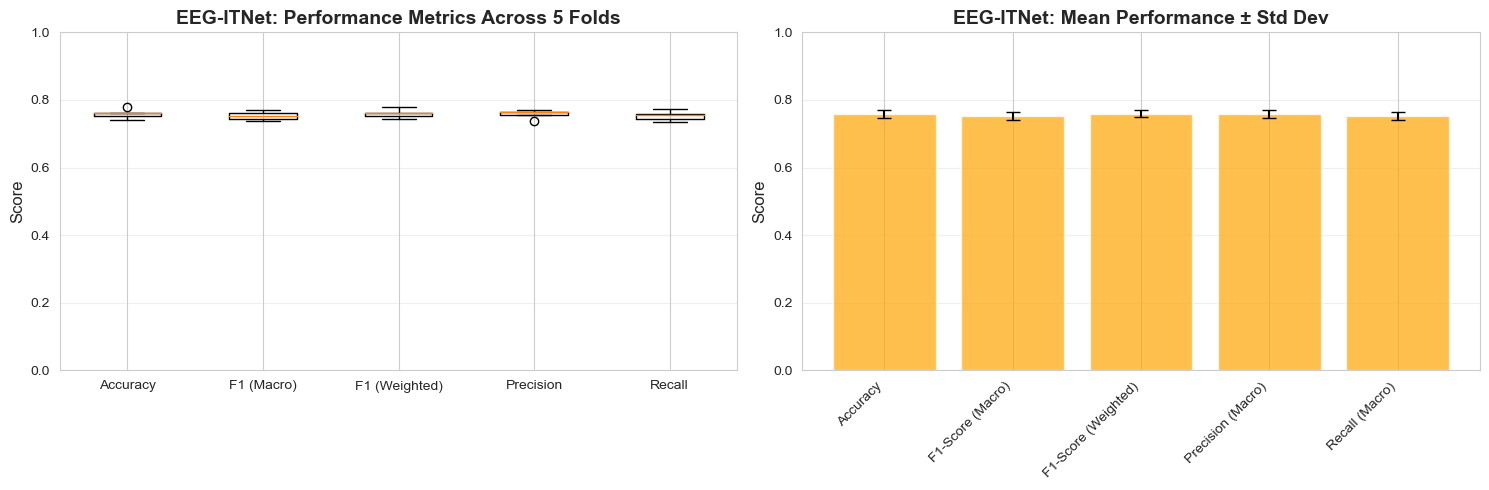

In [9]:
# Calculate mean and std for all metrics
itnet_results_summary = {
    'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
    'Mean': [
        np.mean(itnet_fold_results['accuracy']),
        np.mean(itnet_fold_results['f1_macro']),
        np.mean(itnet_fold_results['f1_weighted']),
        np.mean(itnet_fold_results['precision_macro']),
        np.mean(itnet_fold_results['recall_macro'])
    ],
    'Std': [
        np.std(itnet_fold_results['accuracy']),
        np.std(itnet_fold_results['f1_macro']),
        np.std(itnet_fold_results['f1_weighted']),
        np.std(itnet_fold_results['precision_macro']),
        np.std(itnet_fold_results['recall_macro'])
    ]
}

df_itnet_summary = pd.DataFrame(itnet_results_summary)

print("\n" + "="*60)
print("EEG-ITNET 5-FOLD CROSS-VALIDATION SUMMARY")
print("="*60)
print(df_itnet_summary.to_string(index=False))
print("="*60)

# Visualize results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Box plot of metrics across folds
itnet_metrics_data = pd.DataFrame({
    'Accuracy': itnet_fold_results['accuracy'],
    'F1 (Macro)': itnet_fold_results['f1_macro'],
    'F1 (Weighted)': itnet_fold_results['f1_weighted'],
    'Precision': itnet_fold_results['precision_macro'],
    'Recall': itnet_fold_results['recall_macro']
})

axes[0].boxplot(itnet_metrics_data.values, labels=itnet_metrics_data.columns)
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_title('EEG-ITNet: Performance Metrics Across 5 Folds', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, 1])

# Plot 2: Bar plot with error bars
x_pos = np.arange(len(df_itnet_summary))
axes[1].bar(x_pos, df_itnet_summary['Mean'], yerr=df_itnet_summary['Std'], 
            capsize=5, alpha=0.7, color='orange')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(df_itnet_summary['Metric'], rotation=45, ha='right')
axes[1].set_ylabel('Score', fontsize=12)
axes[1].set_title('EEG-ITNet: Mean Performance ± Std Dev', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

## 9. Training History Visualization

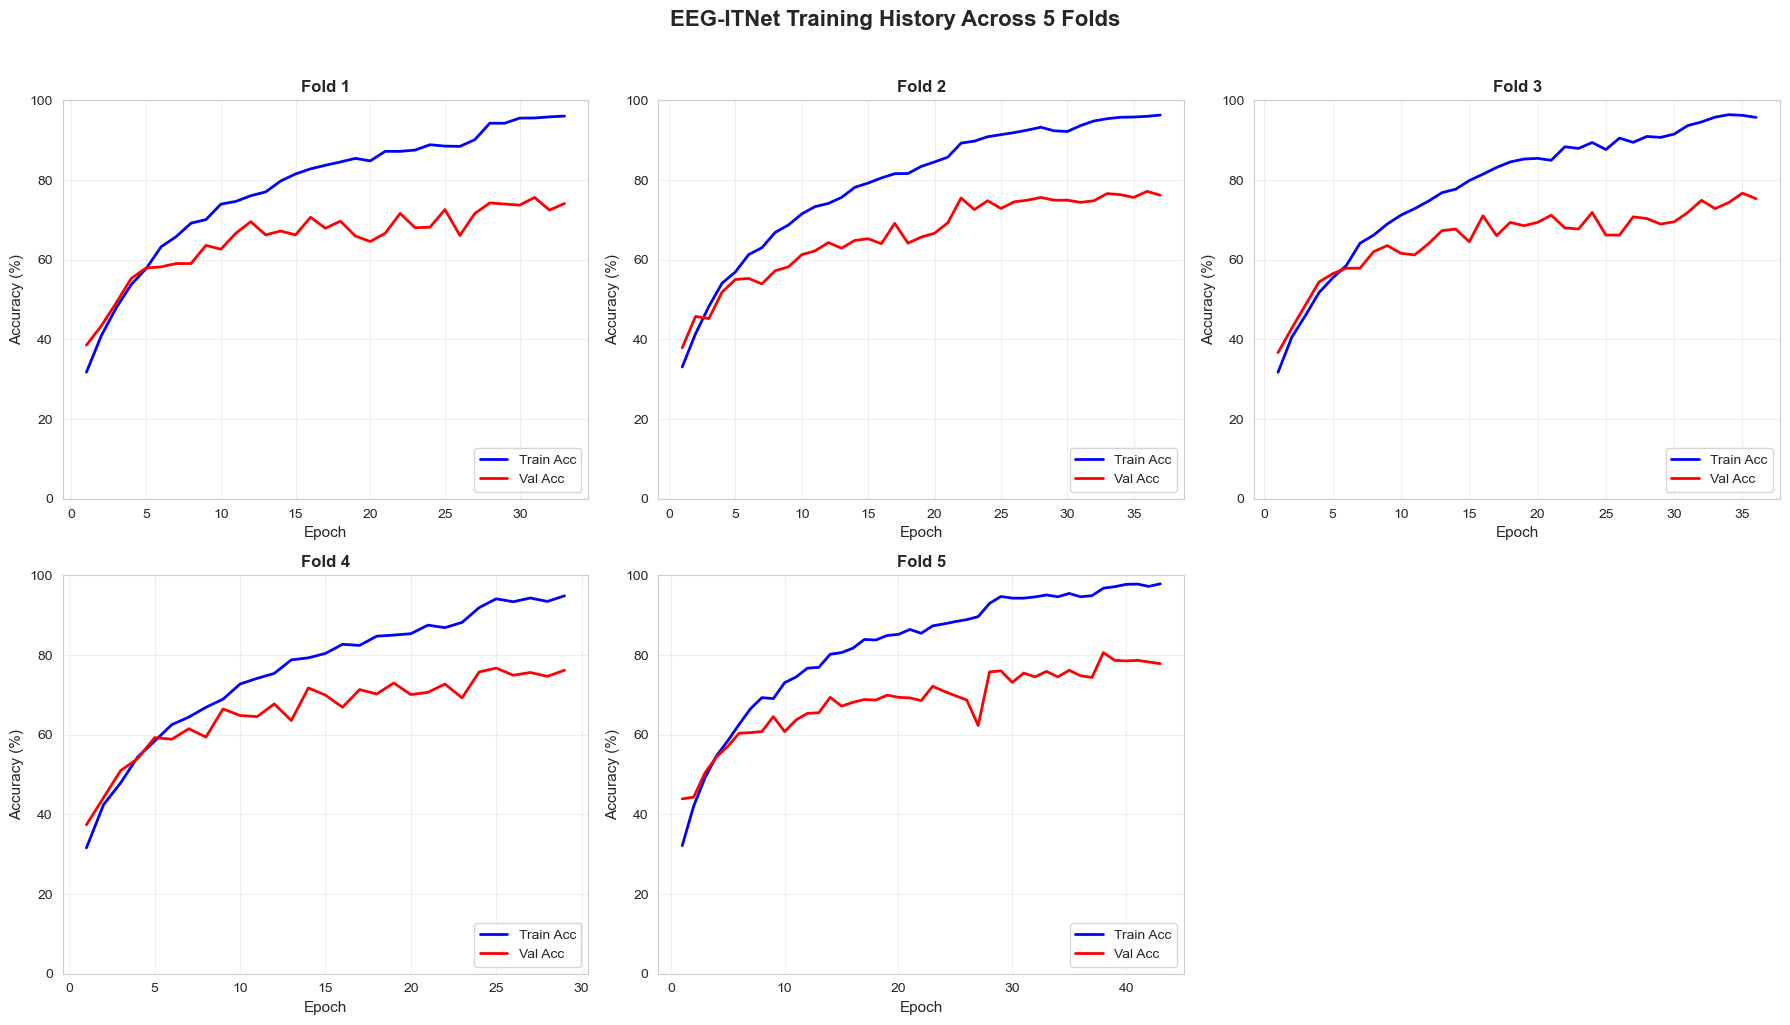

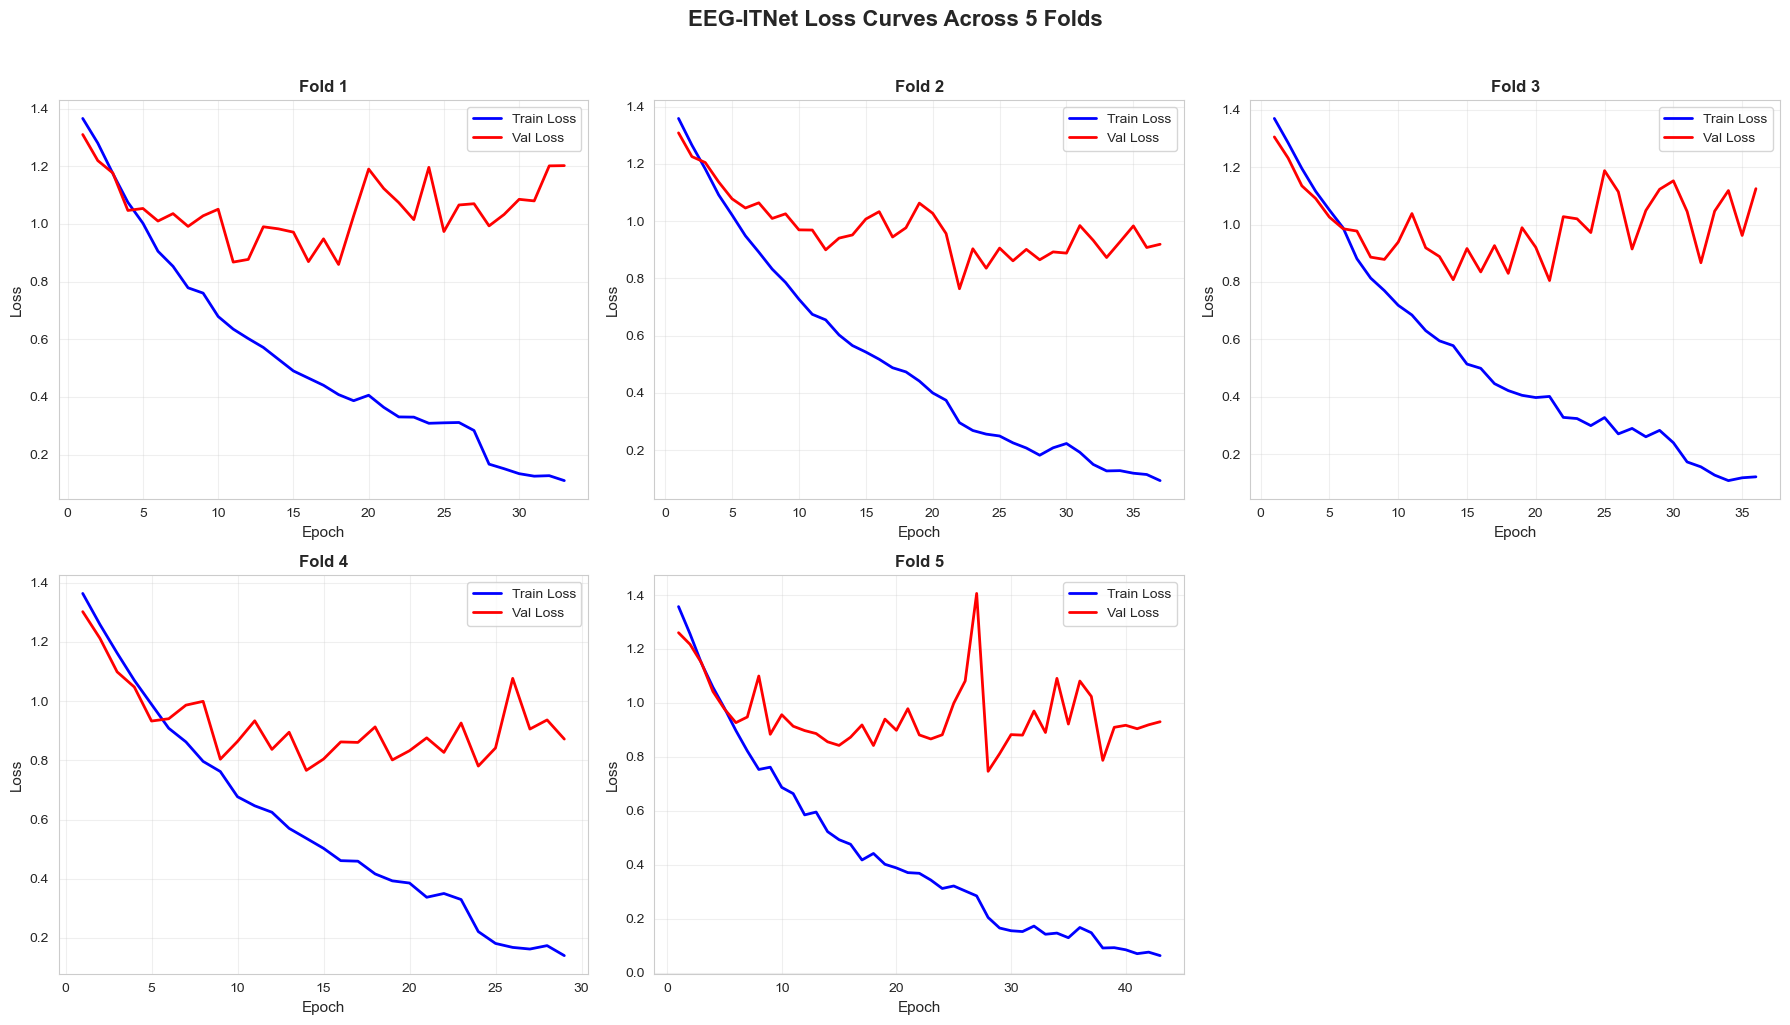

In [10]:
# Plot training history for all folds
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('EEG-ITNet Training History Across 5 Folds', fontsize=16, fontweight='bold', y=1.02)

axes = axes.flatten()

for fold_num in range(n_splits):
    ax = axes[fold_num]
    
    train_history = itnet_fold_results['train_history'][fold_num]
    val_history = itnet_fold_results['val_history'][fold_num]
    
    epochs = range(1, len(train_history['accuracy']) + 1)
    
    # Plot accuracy
    ax.plot(epochs, train_history['accuracy'], 'b-', label='Train Acc', linewidth=2)
    ax.plot(epochs, val_history['accuracy'], 'r-', label='Val Acc', linewidth=2)
    
    ax.set_xlabel('Epoch', fontsize=11)
    ax.set_ylabel('Accuracy (%)', fontsize=11)
    ax.set_title(f'Fold {fold_num + 1}', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right')
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0, 100])

# Remove empty subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

# Plot loss curves
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('EEG-ITNet Loss Curves Across 5 Folds', fontsize=16, fontweight='bold', y=1.02)

axes = axes.flatten()

for fold_num in range(n_splits):
    ax = axes[fold_num]
    
    train_history = itnet_fold_results['train_history'][fold_num]
    val_history = itnet_fold_results['val_history'][fold_num]
    
    epochs = range(1, len(train_history['loss']) + 1)
    
    # Plot loss
    ax.plot(epochs, train_history['loss'], 'b-', label='Train Loss', linewidth=2)
    ax.plot(epochs, val_history['loss'], 'r-', label='Val Loss', linewidth=2)
    
    ax.set_xlabel('Epoch', fontsize=11)
    ax.set_ylabel('Loss', fontsize=11)
    ax.set_title(f'Fold {fold_num + 1}', fontsize=12, fontweight='bold')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

# Remove empty subplot
axes[5].axis('off')

plt.tight_layout()
plt.show()

## 10. Confusion Matrix Visualization

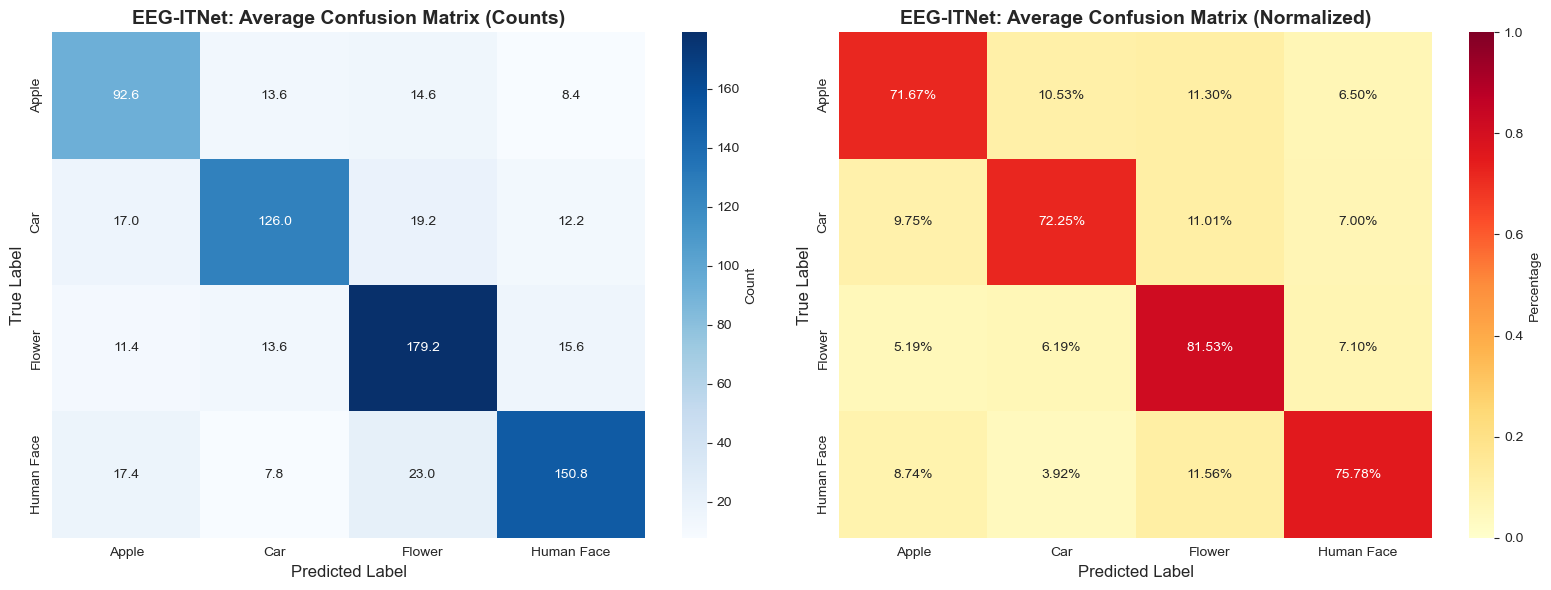


EEG-ITNet Per-Class Accuracy:
  Apple: 71.67%
  Car: 72.25%
  Flower: 81.53%
  Human Face: 75.78%


In [11]:
# Average confusion matrix across all folds
itnet_avg_cm = np.mean(itnet_fold_results['confusion_matrices'], axis=0)
itnet_avg_cm_normalized = itnet_avg_cm / itnet_avg_cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Raw counts
sns.heatmap(itnet_avg_cm, annot=True, fmt='.1f', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('EEG-ITNet: Average Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# Plot 2: Normalized (percentages)
sns.heatmap(itnet_avg_cm_normalized, annot=True, fmt='.2%', cmap='YlOrRd', 
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1], cbar_kws={'label': 'Percentage'}, vmin=0, vmax=1)
axes[1].set_title('EEG-ITNet: Average Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=12)
axes[1].set_xlabel('Predicted Label', fontsize=12)

plt.tight_layout()
plt.show()

# Per-class accuracy
print("\nEEG-ITNet Per-Class Accuracy:")
for i, class_name in enumerate(class_names):
    class_acc = itnet_avg_cm_normalized[i, i]
    print(f"  {class_name}: {class_acc:.2%}")

## 11. Save Results to CSV

In [12]:
print("="*80)
print("SAVING EEG-ITNET RESULTS...")
print("="*80)

# Save summary results
df_itnet_summary.to_csv('itnet_results_summary.csv', index=False)
print("✅ EEG-ITNet Summary saved to: itnet_results_summary.csv")

# Save detailed fold results
itnet_fold_details = pd.DataFrame({
    'Fold': range(1, n_splits + 1),
    'Accuracy': itnet_fold_results['accuracy'],
    'F1_Macro': itnet_fold_results['f1_macro'],
    'F1_Weighted': itnet_fold_results['f1_weighted'],
    'Precision_Macro': itnet_fold_results['precision_macro'],
    'Recall_Macro': itnet_fold_results['recall_macro']
})
itnet_fold_details.to_csv('itnet_fold_details.csv', index=False)
print("✅ EEG-ITNet Fold details saved to: itnet_fold_details.csv")

# Save average confusion matrix
df_itnet_cm = pd.DataFrame(itnet_avg_cm, index=class_names, columns=class_names)
df_itnet_cm.to_csv('itnet_confusion_matrix.csv')
print("✅ EEG-ITNet Confusion matrix saved to: itnet_confusion_matrix.csv")

print("\n" + "="*80)
print("ALL EEG-ITNET RESULTS SAVED SUCCESSFULLY!")
print("="*80)
print("\nSaved files:")
print("  - itnet_results_summary.csv")
print("  - itnet_fold_details.csv")
print("  - itnet_confusion_matrix.csv")
print("="*80)

SAVING EEG-ITNET RESULTS...
✅ EEG-ITNet Summary saved to: itnet_results_summary.csv
✅ EEG-ITNet Fold details saved to: itnet_fold_details.csv
✅ EEG-ITNet Confusion matrix saved to: itnet_confusion_matrix.csv

ALL EEG-ITNET RESULTS SAVED SUCCESSFULLY!

Saved files:
  - itnet_results_summary.csv
  - itnet_fold_details.csv
  - itnet_confusion_matrix.csv
